First, I must create a dataset to do the clustering.
- Overall price level from ICP (25% weight on 2017, 75% on 2021)
- Inflation levels averaged out over the last 10 years from inflation set
- Exchange rate depreciation (frankfurter)
- Exchange rate volatility (standard deviation) (frankfurter)
- GDP per Capita (gdp per capita set)

I will need the ICP, Frankfurter and Inflation datasets that I already created.

In [52]:
import pandas as pd
from pathlib import Path

# ================= importing datasets =================
df_icp = pd.read_csv(Path("icp_pli_tidy.csv"))
df_gdp = pd.read_csv(Path("gdp_per_capita_ppp_yearly.csv"))
df_inf = pd.read_csv(Path("fx_rates_cad.csv"))
df_fx = pd.read_csv(Path("inflation_14_countries.csv"))
# ======================================================

country_codes = ("CAN",
                 "AUS",
                 "USA",
                 "GBR",
                 "TUR",
                 "THA",
                 "ZAF", # south africa
                 "ESP", # spain
                 "GRC",
                 "CHE", # switzerland
                 "CHN",
                 "FRA",
                 "NZL",
                 "JPN"
                 )

# Create a dataframe with country_codes as row names (index)
df = pd.DataFrame(index=country_codes)

In [53]:
# === Overall Price Level Calculation ===


# Filter df_icp for the year 2017
df_icp_2017 = df_icp[df_icp['year'] == 2017]

# Group by Country Code and sum the 'vs_canada' values
icp_2017_sum = df_icp_2017.groupby('Country Code')['vs_canada'].sum()

# Map the summed values to our main DataFrame df
df['icp_2017_sum'] = df.index.map(icp_2017_sum).fillna(0)

# Filter df_icp for the year 2021
df_icp_2021 = df_icp[df_icp['year'] == 2021]

# Group by Country Code and sum the 'vs_canada' values
icp_2021_sum = df_icp_2021.groupby('Country Code')['vs_canada'].sum()

# Map the summed values to our main DataFrame df
df['icp_2021_sum'] = df.index.map(icp_2021_sum).fillna(0)

# Calculate the weighted overall price level (25% weight on 2017, 75% on 2021)
df['price_level'] = ((0.25 * df['icp_2017_sum']) + (0.75 * df['icp_2021_sum']))/5
df = df.drop(columns=["icp_2017_sum", "icp_2021_sum"])

# Display the updated DataFrame
display(df)


,price_level
CAN,100.000000
AUS,110.843951
USA,86.185608
GBR,96.406296
TUR,44.268321
THA,38.541792
ZAF,54.310362
ESP,77.002584
GRC,74.498481
CHE,132.724767


In [54]:
# Identify the columns for the years 2014 to 2024
years_cols = [str(year) for year in range(2014, 2025)]

# Calculate the average GDP per capita for these years for each row
df_gdp['gdp_avg'] = df_gdp[years_cols].mean(axis=1)

# Set 'economy' as index to map values directly to our main dataframe index (country codes)
gdp_mapping = df_gdp.set_index('economy')['gdp_avg']

# Map the average GDP values to our main DataFrame
df['gdp_avg'] = df.index.map(gdp_mapping)

# Display the updated DataFrame
display(df)

,price_level,gdp_avg
CAN,100.000000,56710.689993
AUS,110.843951,57917.172122
USA,86.185608,68832.833660
GBR,96.406296,51887.891458
TUR,44.268321,29900.552832
THA,38.541792,20259.615059
ZAF,54.310362,14105.379209
ESP,77.002584,45059.745253
GRC,74.498481,33297.161320
CHE,132.724767,81559.847039


In [55]:
import numpy as np
import pandas as pd

country_to_currency = {
    "CAN": "CAD",
    "AUS": "AUD",
    "USA": "USD",
    "GBR": "GBP",
    "TUR": "TRY",
    "THA": "THB",
    "ZAF": "ZAR",
    "ESP": "EUR",
    "GRC": "EUR",
    "CHE": "CHF",
    "CHN": "CNY",
    "FRA": "EUR",
    "NZL": "NZD",
    "JPN": "JPY"
}

# Read fx rates dataset
df_rates = pd.read_csv('fx_rates_cad.csv')
date_col = df_rates.columns[0]
df_rates[date_col] = pd.to_datetime(df_rates[date_col])

# Sort by date to allow backward/forward fill or exact indexing
df_rates = df_rates.sort_values(by=date_col).reset_index(drop=True)

# Locate exact dates or find the nearest ones available
target_start = pd.to_datetime('2014-01-02')
target_end = pd.to_datetime('2026-10-16')

# Get indices of closest matching dates
start_idx = (df_rates[date_col] - target_start).abs().idxmin()
end_idx = (df_rates[date_col] - target_end).abs().idxmin()

start_row = df_rates.loc[start_idx]
end_row = df_rates.loc[end_idx]

print(f"Using start date: {start_row[date_col].strftime('%Y-%m-%d')}")
print(f"Using end date: {end_row[date_col].strftime('%Y-%m-%d')}")

log_changes = {}
for country, currency in country_to_currency.items():
    if currency == "CAD":
        log_changes[country] = 0.0
    else:
        try:
            s_start = float(start_row[currency])
            s_end = float(end_row[currency])
            log_changes[country] = np.log(s_end / s_start)
        except Exception as e:
            log_changes[country] = np.nan

# Map log change values to df
df['exchange_depr'] = df.index.map(log_changes)

# Display updated DataFrame
display(df)

Using start date: 2014-12-31
Using end date: 2026-10-16


,price_level,gdp_avg,exchange_depr
CAN,100.000000,56710.689993,0.000000
AUS,110.843951,57917.172122,-0.038375
USA,86.185608,68832.833660,-0.200927
GBR,96.406296,51887.891458,-0.044865
TUR,44.268321,29900.552832,2.854610
THA,38.541792,20259.615059,-0.184530
ZAF,54.310362,14105.379209,0.150849
ESP,77.002584,45059.745253,-0.124976
GRC,74.498481,33297.161320,-0.124976
CHE,132.724767,81559.847039,-0.384883


In [56]:
# average inflation rate
country_to_code = {
    "Canada": "CAN",
    "Australia": "AUS",
    "United States": "USA",
    "United Kingdom": "GBR",
    "Turkey": "TUR",
    "Thailand": "THA",
    "South Africa": "ZAF",
    "Spain": "ESP",
    "Greece": "GRC",
    "Switzerland": "CHE",
    "China": "CHN",
    "France": "FRA",
    "New Zealand": "NZL",
    "Japan": "JPN"
}

# Filter df_fx for years 2014 to 2025
df_inf_filtered = df_fx[(df_fx['year'] >= 2014) & (df_fx['year'] <= 2025)]

# Calculate the average inflation for each country column
mean_inflation = df_inf_filtered.drop(columns=['year']).mean()

# Create a dictionary mapping country codes to average inflation rates
inflation_map = {}
for country, code in country_to_code.items():
    if country in mean_inflation:
        inflation_map[code] = mean_inflation[country]

# Map the calculated averages to our main DataFrame df
df['inflation_avg'] = df.index.map(inflation_map)

# Display the updated DataFrame
display(df)

,price_level,gdp_avg,exchange_depr,inflation_avg
CAN,100.000000,56710.689993,0.000000,2.460243
AUS,110.843951,57917.172122,-0.038375,2.723886
USA,86.185608,68832.833660,-0.200927,2.762495
GBR,96.406296,51887.891458,-0.044865,2.899567
TUR,44.268321,29900.552832,2.854610,26.532122
THA,38.541792,20259.615059,-0.184530,0.964506
ZAF,54.310362,14105.379209,0.150849,4.965521
ESP,77.002584,45059.745253,-0.124976,1.968097
GRC,74.498481,33297.161320,-0.124976,1.369582
CHE,132.724767,81559.847039,-0.384883,0.523697


In [57]:
# Calculate the standard deviation (volatility) of exchange rates from 2014 to today
# Target date range: 2014-01-01 to today
target_start_date = pd.to_datetime('2014-01-01')
today_date = pd.Timestamp.now()

# Filter df_rates for dates between 2014 and today
date_col = df_rates.columns[0]
df_rates_filtered = df_rates[(df_rates[date_col] >= target_start_date) & (df_rates[date_col] <= today_date)]

# Calculate standard deviation for each currency column
std_rates = df_rates_filtered.drop(columns=[date_col]).std()

# Map standard deviations to country codes using country_to_currency
volatility_map = {}
for country, currency in country_to_currency.items():
    if currency == "CAD":
        volatility_map[country] = 0.0
    elif currency in std_rates:
        volatility_map[country] = std_rates[currency]
    else:
        volatility_map[country] = np.nan

# Add the volatility column to df
df['exchange_vol'] = df.index.map(volatility_map)

# Display the updated DataFrame
display(df)

,price_level,gdp_avg,exchange_depr,inflation_avg,exchange_vol
CAN,100.000000,56710.689993,0.000000,2.460243,0.000000
AUS,110.843951,57917.172122,-0.038375,2.723886,0.045491
USA,86.185608,68832.833660,-0.200927,2.762495,0.030396
GBR,96.406296,51887.891458,-0.044865,2.899567,0.034243
TUR,44.268321,29900.552832,2.854610,26.532122,10.442438
THA,38.541792,20259.615059,-0.184530,0.964506,1.501722
ZAF,54.310362,14105.379209,0.150849,4.965521,1.304060
ESP,77.002584,45059.745253,-0.124976,1.968097,0.032388
GRC,74.498481,33297.161320,-0.124976,1.369582,0.032388
CHE,132.724767,81559.847039,-0.384883,0.523697,0.063392


In [58]:
# save dataset
df.to_csv("clustering_set.csv")

In [59]:
from sklearn.cluster import KMeans
import pandas as pd

df = pd.read_csv("clustering_set.csv")

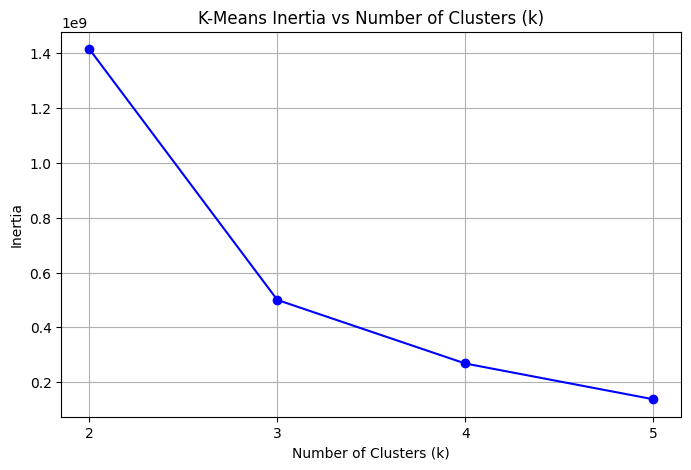

In [60]:
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans

# Prepare the features for clustering by dropping non-numeric or index-like columns
# Based on df structure, the first column might be the country codes if loaded from csv
features = df.select_dtypes(include=['float64', 'int64'])

# If there are NaN values, let's fill them (e.g., with 0 or mean) to prevent KMeans from failing
features = features.fillna(features.mean())

k_values = [2, 3, 4, 5]
inertia_values = []

for k in k_values:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(features)
    inertia_values.append(kmeans.inertia_)

# Plotting the elbow curve
plt.figure(figsize=(8, 5))
plt.plot(k_values, inertia_values, marker='o', linestyle='-', color='b')
plt.title('K-Means Inertia vs Number of Clusters (k)')
plt.xlabel('Number of Clusters (k)')
plt.ylabel('Inertia')
plt.xticks(k_values)
plt.grid(True)
plt.show()

We will choose k=3, because this is the "elbow" of the curve. This is the point where we optimize the tradeoff of minimizing error and adding too many clusters.

In [61]:
from sklearn.cluster import KMeans
import pandas as pd

# 1. Prepare features from the DataFrame (excluding non-numeric country identifier column)
# df was read from 'clustering_set.csv', so 'Unnamed: 0' stores the country codes
country_col = 'Unnamed: 0' if 'Unnamed: 0' in df.columns else df.index.name
features = df.select_dtypes(include=['float64', 'int64'])

# Handle missing values by filling with column mean
features = features.fillna(features.mean())

# 2. Fit KMeans with k = 3
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
df['cluster'] = kmeans.fit_predict(features)

# 3. Report and display results
print("--- KMeans Clustering Results (k=3) ---")
for cluster_id in sorted(df['cluster'].unique()):
    countries_in_cluster = df[df['cluster'] == cluster_id]['Unnamed: 0'].tolist()
    print(f"\nCluster {cluster_id}:")
    print(f"Countries: {countries_in_cluster}")
    print("Cluster Metrics (Average):")
    display(df[df['cluster'] == cluster_id].drop(columns=['Unnamed: 0', 'cluster']).mean())

--- KMeans Clustering Results (k=3) ---

Cluster 0:
Countries: ['TUR', 'THA', 'ZAF', 'GRC', 'CHN']
Cluster Metrics (Average):


,0
price_level,54.537261
gdp_avg,23259.279647
exchange_depr,0.513884
inflation_avg,7.063219
exchange_vol,2.688683



Cluster 1:
Countries: ['CAN', 'AUS', 'GBR', 'ESP', 'FRA', 'NZL', 'JPN']
Cluster Metrics (Average):


,0
price_level,98.688642
gdp_avg,50948.485520
exchange_depr,-0.019152
inflation_avg,2.248235
exchange_vol,1.751593



Cluster 2:
Countries: ['USA', 'CHE']
Cluster Metrics (Average):


,0
price_level,109.455188
gdp_avg,75196.340349
exchange_depr,-0.292905
inflation_avg,1.643096
exchange_vol,0.046894


The results we get from this clustering are very significant. Cluster 0 has the lowest price levels, lowest gdp, highest exchange rate depreciation,  highest inflation and highest volattility. Cluster 1 has normal values and cluster 2 has the beste of these values.
We can define cluster 0 as high value travel countries, cluster 1 as medium value and 2 as low value.